In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt, seaborn as sns

In [6]:
df=pd.read_csv("/content/listings.csv.gz")
df
print(df.shape)
print(df.info())

(29918, 90)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29918 entries, 0 to 29917
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            29918 non-null  int64  
 1   listing_url                                   29918 non-null  object 
 2   scrape_id                                     29918 non-null  int64  
 3   last_scraped                                  29918 non-null  object 
 4   source                                        8906 non-null   object 
 5   name                                          29917 non-null  object 
 6   description                                   29772 non-null  object 
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   29918 non-null  object 
 9   host_id                                       299

In [7]:
df.isnull().sum().head(20)

,0
id,0
listing_url,0
scrape_id,0
last_scraped,0
source,21012
name,1
description,146
neighborhood_overview,29918
picture_url,0
host_id,0


In [8]:
cols = ["price","neighbourhood_cleansed","room_type","accommodates","bedrooms",
        "bathrooms_text","amenities","host_is_superhost","host_response_rate",
        "host_since","minimum_nights","number_of_reviews","review_scores_rating",
        "availability_365","instant_bookable"]
df=df[cols].copy()
df

,price,neighbourhood_cleansed,room_type,accommodates,bedrooms,bathrooms_text,amenities,host_is_superhost,host_response_rate,host_since,minimum_nights,number_of_reviews,review_scores_rating,availability_365,instant_bookable
0,NaN,East Flatbush,Entire home/apt,4,3.0,1.5 baths,"[""Kitchen"", ""Fire extinguisher"", ""Free parking...",f,NaN,NaN,30.0,0,NaN,365,NaN
1,$164.55,Maspeth,Private room,5,2.0,1 private bath,"[""TV"", ""Kitchen"", ""Fire extinguisher"", ""Air co...",f,NaN,NaN,31.0,0,NaN,364,NaN
2,NaN,Crown Heights,Private room,2,1.0,1.5 baths,"[""TV"", ""Kitchen"", ""Fire extinguisher"", ""First ...",f,NaN,NaN,30.0,0,NaN,269,NaN
3,NaN,Gramercy,Entire home/apt,3,1.0,1 bath,"[""TV"", ""Heating"", ""Kitchen"", ""Air conditioning...",f,NaN,NaN,30.0,8,4.38,0,NaN
4,NaN,Flatlands,Private room,1,1.0,1 bath,"[""TV"", ""Heating"", ""Refrigerator"", ""Microwave"",...",f,NaN,NaN,80.0,36,4.50,0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29913,NaN,Financial District,Private room,2,1.0,1 shared bath,"[""Hair dryer"", ""Building staff"", ""Clothing sto...",f,NaN,NaN,1.0,0,NaN,119,NaN
29914,$689.00,Upper West Side,Private room,2,1.0,1 private bath,"[""Hair dryer"", ""Building staff"", ""Self check-i...",f,NaN,NaN,1.0,0,NaN,307,NaN
29915,$789.00,Upper West Side,Private room,4,1.0,1 private bath,"[""Hair dryer"", ""Building staff"", ""Self check-i...",f,NaN,NaN,1.0,0,NaN,334,NaN
29916,"$2,369.82",Financial District,Private room,4,1.0,1 private bath,"[""Hair dryer"", ""Building staff"", ""Self check-i...",f,NaN,NaN,1.0,1,5.00,12,NaN


Cleaning

In [9]:
df.isnull().sum()

,0
price,10512
neighbourhood_cleansed,0
room_type,0
accommodates,0
bedrooms,39
bathrooms_text,107
amenities,0
host_is_superhost,0
host_response_rate,29918
host_since,29918


In [12]:
# Price: "$2,500.00" -> 2500.0
df["price"]=df["price"].astype(str).str.replace(r"[\$,]", "", regex=True).astype(float)

# response rate -> "95%" to 0.95 (handling cases where all values are NaN)
df["host_response_rate"] = df["host_response_rate"].astype(str).str.rstrip("%").replace("nan", np.nan).astype(float) / 100


# 't'/'f' -> 1/0
for c in ["host_is_superhost", "instant_bookable"]:
    df[c] = df[c].map({"t": 1, "f": 0})

/tmp/ipykernel_5093/2682257226.py:5: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df["host_response_rate"] = df["host_response_rate"].astype(str).str.rstrip("%").replace("nan", np.nan).astype(float) / 100


In [16]:
# To make this cell safe to re-run, we ensure the columns exist before processing
if "bathrooms_text" in df.columns:
    # Bathrooms: "1.5 shared baths" -> 1.5, "Half-bath" -> 0.5
    df["bathrooms"] = (df["bathrooms_text"].str.replace("Half-bath", "0.5", case=False)
                       .str.extract(r"(\d+\.?\d*)")[0].astype(float))
    df["shared_bath"] = df["bathrooms_text"].str.contains("shared", case=False, na=False).astype(int)

if "host_since" in df.columns:
    # Dates -> numeric: years as a host
    df["host_years"] = (pd.Timestamp.today() - pd.to_datetime(df["host_since"])).dt.days / 365

if "amenities" in df.columns:
    # Amenities -> count (and 2-3 key flags)
    df["n_amenities"] = df["amenities"].str.count(",") + 1
    df["has_ac"]   = df["amenities"].str.contains("Air conditioning", case=False, na=False).astype(int)
    df["has_wifi"] = df["amenities"].str.contains("Wifi", case=False, na=False).astype(int)

# Safely drop columns if they still exist in df
existing_cols_to_drop = [col for col in ["bathrooms_text","amenities","host_since"] if col in df.columns]
if existing_cols_to_drop:
    df = df.drop(columns=existing_cols_to_drop)

df = df.drop_duplicates().dropna(subset=["price"])
df = df[df["price"] > 0]


#outliers


In [17]:
Q1, Q3 = df["price"].quantile([0.25, 0.75]); IQR = Q3 - Q1
low, high = Q1 - 1.5*IQR, Q3 + 1.5*IQR
print((df["price"] > high).sum(), "IQR outliers")

1636 IQR outliers


In [18]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
sns.set_style("whitegrid")

df["log_price"] = np.log1p(df["price"])

# For readable plots, cap the extreme tail (this is only for plotting, not the data)
cap = df["price"].quantile(0.99)
plot_df = df[df["price"] <= cap]

1. price distribution: raw vs log

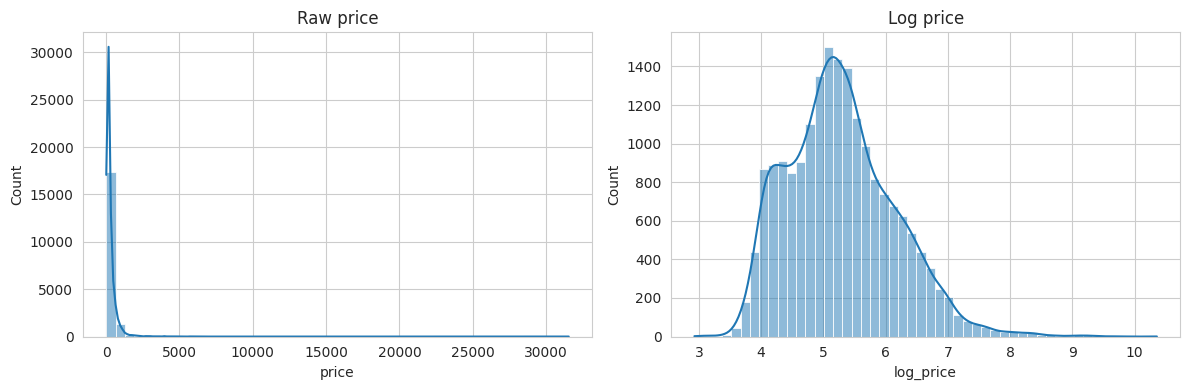

Skew raw: 18.04 | Skew log: 0.58


In [19]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["price"], bins=50, kde=True, ax=ax[0]); ax[0].set_title("Raw price")
sns.histplot(df["log_price"], bins=50, kde=True, ax=ax[1]); ax[1].set_title("Log price")
plt.tight_layout(); plt.show()
print("Skew raw:", df["price"].skew().round(2), "| Skew log:", df["log_price"].skew().round(2))

2. room type vs price


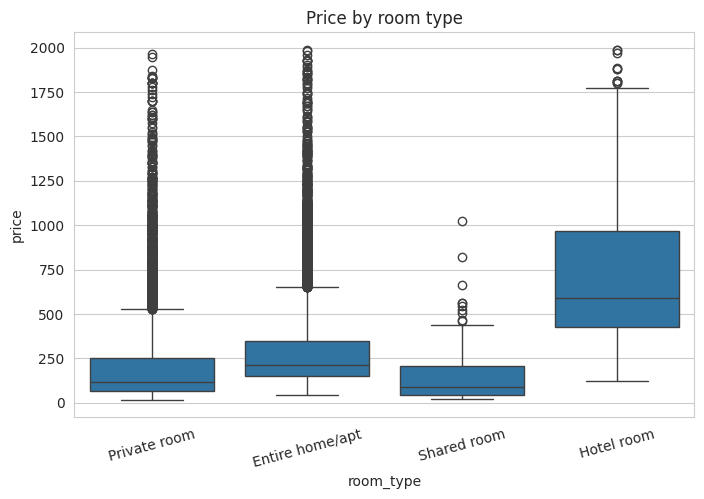

room_type
Hotel room         646.000
Entire home/apt    216.395
Private room       116.500
Shared room         91.120
Name: price, dtype: float64


In [20]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="room_type", y="price", data=plot_df)
plt.title("Price by room type"); plt.xticks(rotation=15); plt.show()
print(df.groupby("room_type")["price"].median().sort_values(ascending=False))

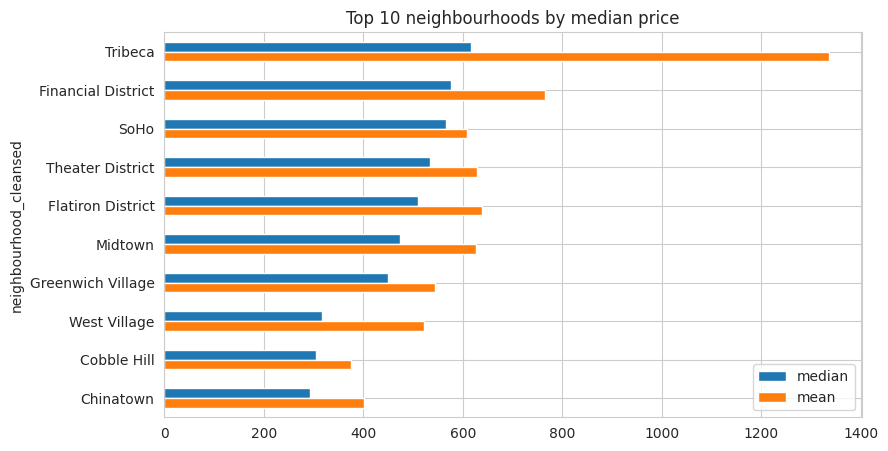

In [21]:
g = df.groupby("neighbourhood_cleansed")["price"].agg(["median", "mean", "count"])
g = g[g["count"] >= 20]                      # ignore tiny neighbourhoods
top10 = g.nlargest(10, "median")
top10[["median", "mean"]].plot.barh(figsize=(9, 5)).invert_yaxis()
plt.title("Top 10 neighbourhoods by median price"); plt.show()

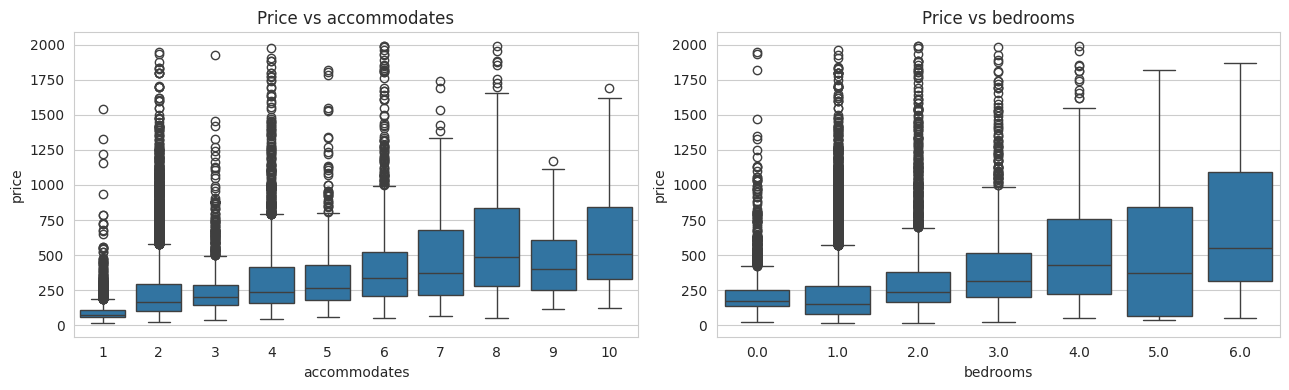

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(x="accommodates", y="price", data=plot_df[plot_df["accommodates"] <= 10], ax=ax[0])
sns.boxplot(x="bedrooms", y="price", data=plot_df[plot_df["bedrooms"] <= 6], ax=ax[1])
ax[0].set_title("Price vs accommodates"); ax[1].set_title("Price vs bedrooms")
plt.tight_layout(); plt.show()

do superhost charge more?

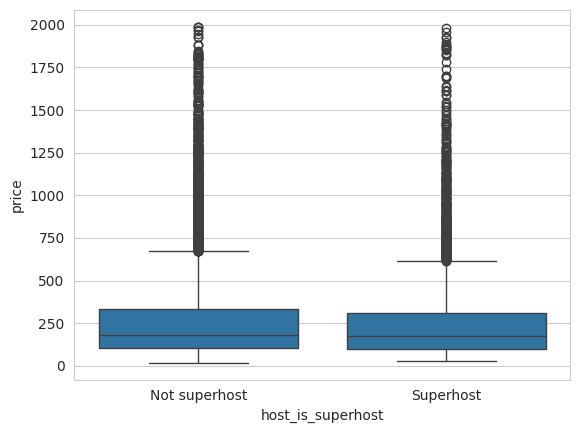

host_is_superhost
0    184.270
1    175.585
Name: price, dtype: float64


In [23]:
sns.boxplot(x="host_is_superhost", y="price", data=plot_df)
plt.xticks([0, 1], ["Not superhost", "Superhost"]); plt.show()
print(df.groupby("host_is_superhost")["price"].median())

correlation heatmap and multicollinearity

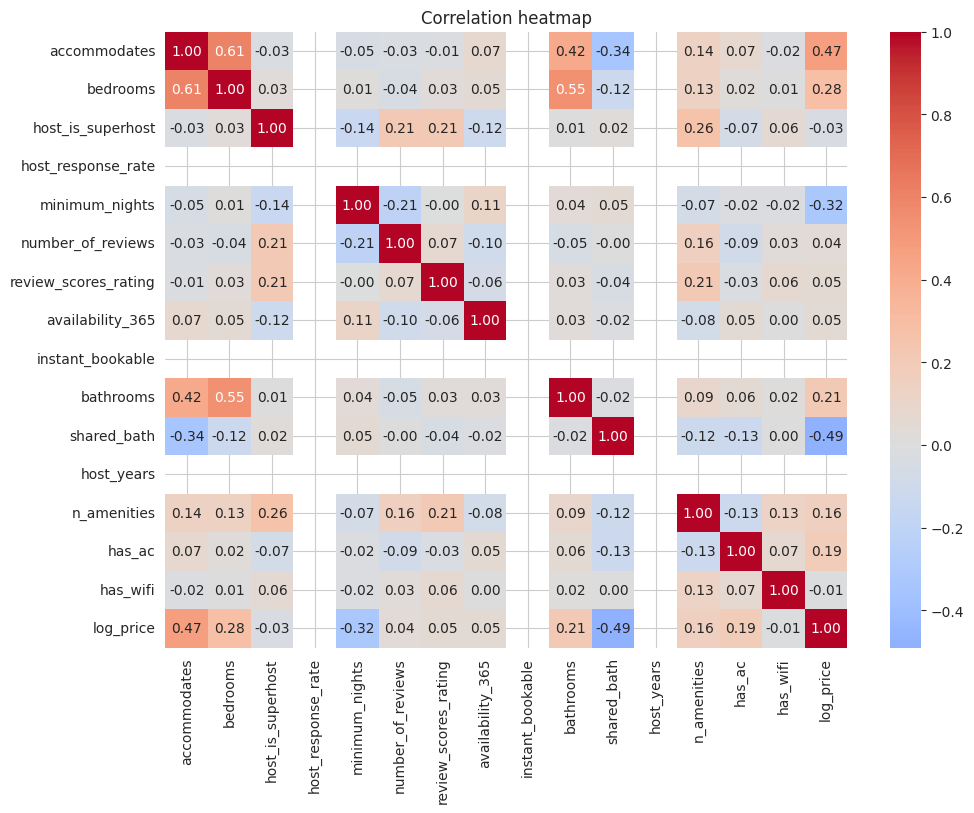

Series([], dtype: float64)


In [24]:
num_df = df.select_dtypes("number").drop(columns=["price"])   # log_price stays as the target
plt.figure(figsize=(11, 8))
sns.heatmap(num_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap"); plt.show()

# Strongly correlated feature pairs (|r| > 0.7)
c = num_df.corr().abs()
pairs = c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack()
print(pairs[pairs > 0.7].sort_values(ascending=False))

Do more amenities mean a higher price?

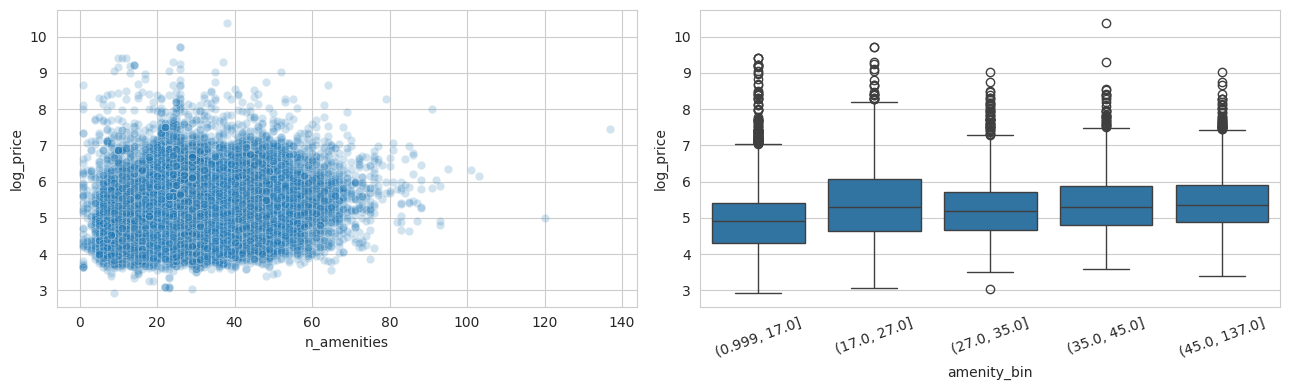

Correlation: 0.16


In [25]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(x="n_amenities", y="log_price", data=df, alpha=0.2, ax=ax[0])
df["amenity_bin"] = pd.qcut(df["n_amenities"], 5, duplicates="drop")
sns.boxplot(x="amenity_bin", y="log_price", data=df, ax=ax[1])
ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
print("Correlation:", df["n_amenities"].corr(df["log_price"]).round(2))
df = df.drop(columns="amenity_bin")          # drop helper so it doesn't enter the model

IQR limits: -239 to 676 -> 1636 outliers
Z-score (|z|>3) -> 185 outliers


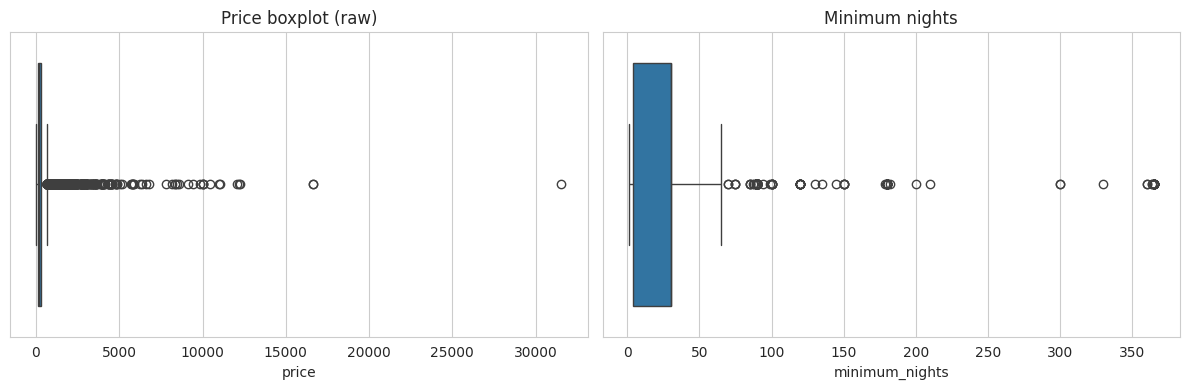

Rows before: 19127 | after: 18936


In [27]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats

# Missingness flag (skip if you already added it)
df["no_reviews"] = df["review_scores_rating"].isnull().astype(int)

df_all = df.copy()          # keep a copy WITH outliers for the comparison in Cell 5

# --- Detect: IQR vs z-score on price ---
Q1, Q3 = df["price"].quantile([0.25, 0.75]); IQR = Q3 - Q1
low, high = Q1 - 1.5*IQR, Q3 + 1.5*IQR
iqr_out = ((df["price"] < low) | (df["price"] > high)).sum()
z_out = (np.abs(stats.zscore(df["price"])) > 3).sum()
print(f"IQR limits: {low:.0f} to {high:.0f} -> {iqr_out} outliers")
print(f"Z-score (|z|>3) -> {z_out} outliers")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=df["price"], ax=ax[0]); ax[0].set_title("Price boxplot (raw)")
sns.boxplot(x=df["minimum_nights"], ax=ax[1]); ax[1].set_title("Minimum nights")
plt.tight_layout(); plt.show()

# --- Decision (justify this in a markdown cell) ---
# Price: IQR removes too many genuine luxury listings, z-score is distorted by the extremes.
# Compromise: drop only the top 1% (likely data errors / one-off listings).
cap = df["price"].quantile(0.99)
df = df[df["price"] <= cap].copy()
# minimum_nights: cap at 365 instead of dropping rows
df["minimum_nights"] = df["minimum_nights"].clip(upper=365)

df["log_price"] = np.log1p(df["price"])
print("Rows before:", len(df_all), "| after:", len(df))

In [28]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score

cat_cols = ["neighbourhood_cleansed", "room_type"]

def make_Xy(d):
    d = d.copy()
    y = d["log_price"]
    X = d.drop(columns=["price", "log_price"])          # never keep the target in X
    top = X["neighbourhood_cleansed"].value_counts().nlargest(15).index
    X["neighbourhood_cleansed"] = X["neighbourhood_cleansed"].where(
        X["neighbourhood_cleansed"].isin(top), "Other")
    return X, y

def make_preprocessor(X):
    num_cols = [c for c in X.select_dtypes("number").columns if c not in cat_cols]
    num = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())])
    cat = Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                    ("oh", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", num, num_cols), ("cat", cat, cat_cols)])

X, y = make_Xy(df)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=42)
pre = make_preprocessor(X)
print(Xtr.shape, Xte.shape)

(15148, 18) (3788, 18)


In [29]:
models = {
    "Baseline (mean)": DummyRegressor(),
    "Linear":          LinearRegression(),
    "Ridge":           Ridge(alpha=1.0),
    "RF depth=4":      RandomForestRegressor(max_depth=4, random_state=42, n_jobs=-1),
    "RF full":         RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
}

rows = []
for name, m in models.items():
    p = Pipeline([("pre", pre), ("m", m)]).fit(Xtr, ytr)
    pred = p.predict(Xte)
    rows.append({
        "Model": name,
        "Train R2": p.score(Xtr, ytr),
        "Test R2": p.score(Xte, yte),
        "Test MAE (log)": mean_absolute_error(yte, pred),
        "Test MAE (price)": mean_absolute_error(np.expm1(yte), np.expm1(pred)),
    })
results = pd.DataFrame(rows).round(3).set_index("Model")
results

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['host_response_rate' 'instant_bookable' 'host_years']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['host_response_rate' 'instant_bookable' 'host_years']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['host_response_rate' 'instant_bookable' 'host_years']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['host_response_rate' 'in

,Train R2,Test R2,Test MAE (log),Test MAE (price)
Model,,,,
Baseline (mean),0.000,-0.000,0.649,157.970
Linear,0.555,0.524,0.415,110.346
Ridge,0.555,0.524,0.415,110.346
RF depth=4,0.594,0.586,0.397,109.193
RF full,0.962,0.731,0.303,84.757


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['host_response_rate' 'instant_bookable' 'host_years']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['host_response_rate' 'instant_bookable' 'host_years']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['host_response_rate' 'instant_bookable' 'host_years']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['host_response_rate' 'in

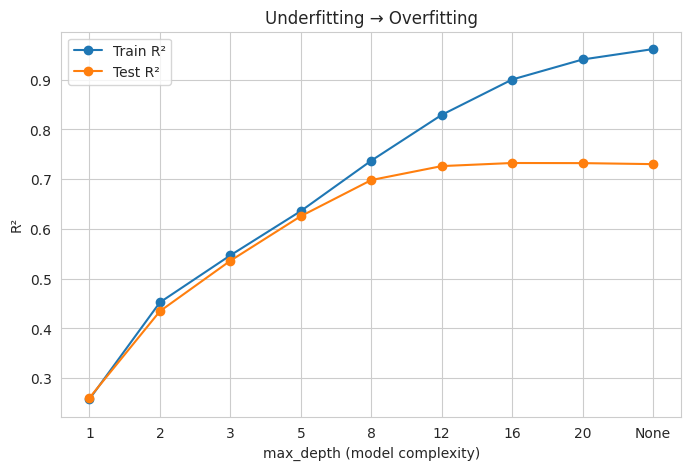

In [30]:
depths = [1, 2, 3, 5, 8, 12, 16, 20, None]
tr_r2, te_r2 = [], []
for d in depths:
    p = Pipeline([("pre", pre),
                  ("m", RandomForestRegressor(n_estimators=100, max_depth=d,
                                              random_state=42, n_jobs=-1))]).fit(Xtr, ytr)
    tr_r2.append(p.score(Xtr, ytr)); te_r2.append(p.score(Xte, yte))

labels = [str(d) for d in depths]
plt.figure(figsize=(8, 5))
plt.plot(labels, tr_r2, marker="o", label="Train R²")
plt.plot(labels, te_r2, marker="o", label="Test R²")
plt.xlabel("max_depth (model complexity)"); plt.ylabel("R²")
plt.title("Underfitting → Overfitting"); plt.legend(); plt.show()

In [31]:
def run_rf(d, label):
    X_, y_ = make_Xy(d)
    a, b, c, e = train_test_split(X_, y_, test_size=0.2, random_state=42)
    p = Pipeline([("pre", make_preprocessor(X_)),
                  ("m", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))]).fit(a, c)
    pred = p.predict(b)
    print(f"{label:22} test R2={r2_score(e, pred):.3f}  MAE(log)={mean_absolute_error(e, pred):.3f}")

run_rf(df_all, "With outliers")
run_rf(df, "Outliers handled")

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['host_response_rate' 'instant_bookable' 'host_years']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['host_response_rate' 'instant_bookable' 'host_years']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


With outliers          test R2=0.732  MAE(log)=0.311


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['host_response_rate' 'instant_bookable' 'host_years']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['host_response_rate' 'instant_bookable' 'host_years']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Outliers handled       test R2=0.731  MAE(log)=0.303


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['host_response_rate' 'instant_bookable' 'host_years']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


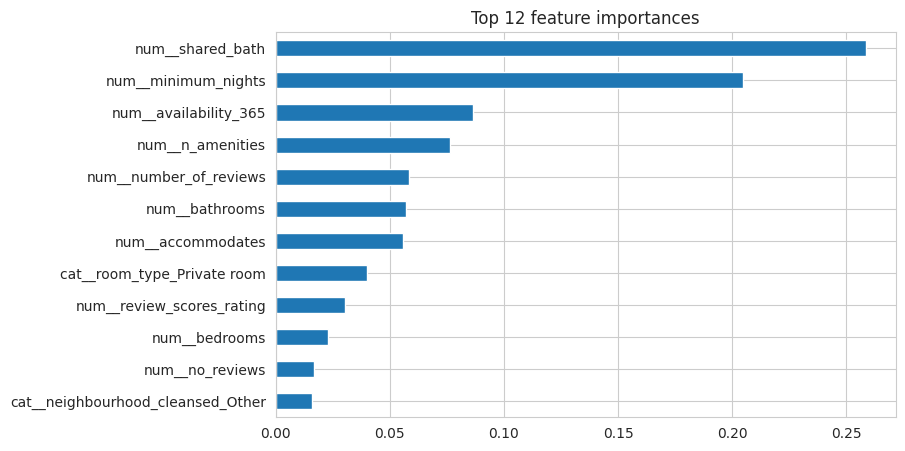

In [32]:
best = Pipeline([("pre", pre),
                 ("m", RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1))]).fit(Xtr, ytr)
names = best.named_steps["pre"].get_feature_names_out()
imp = pd.Series(best.named_steps["m"].feature_importances_, index=names).nlargest(12)
imp.plot.barh(figsize=(8, 5)).invert_yaxis()
plt.title("Top 12 feature importances"); plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['host_response_rate' 'instant_bookable' 'host_years']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


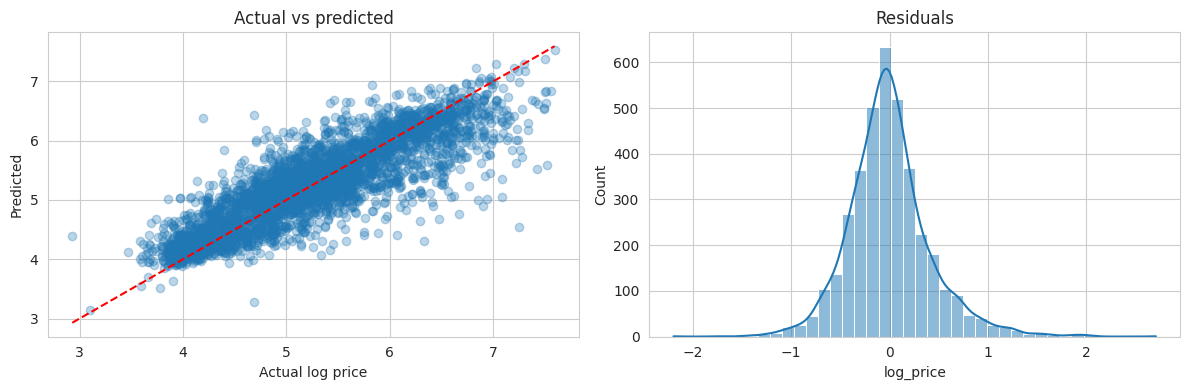

In [33]:
pred = best.predict(Xte)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(yte, pred, alpha=0.3); ax[0].plot([yte.min(), yte.max()], [yte.min(), yte.max()], "r--")
ax[0].set_xlabel("Actual log price"); ax[0].set_ylabel("Predicted"); ax[0].set_title("Actual vs predicted")
sns.histplot(yte - pred, bins=40, kde=True, ax=ax[1]); ax[1].set_title("Residuals")
plt.tight_layout(); plt.show()

In [34]:
from sklearn.model_selection import RandomizedSearchCV

pipe = Pipeline([("pre", pre), ("m", RandomForestRegressor(random_state=42, n_jobs=-1))])
params = {"m__n_estimators": [100, 200, 300],
          "m__max_depth": [8, 12, 16, None],
          "m__min_samples_leaf": [1, 3, 5]}
search = RandomizedSearchCV(pipe, params, n_iter=8, cv=3, scoring="r2", random_state=42, n_jobs=-1)
search.fit(Xtr, ytr)
print("Best params:", search.best_params_)
print("CV R2:", round(search.best_score_, 3), "| Test R2:", round(search.score(Xte, yte), 3))

/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['host_response_rate' 'instant_bookable' 'host_years']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(


Best params: {'m__n_estimators': 200, 'm__min_samples_leaf': 3, 'm__max_depth': None}
CV R2: 0.731 | Test R2: 0.734


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_base.py:635: UserWarning: Skipping features without any observed values: ['host_response_rate' 'instant_bookable' 'host_years']. At least one non-missing value is needed for imputation with strategy='median'.
  warnings.warn(
